# Étape 3 — Modèle LSTM : même tâche, mémoire à long terme

Architecture (tableau, partie 3) :

```
c0 = 0 →  [LSTM 16 unités] → c1 → [LSTM 16 unités] → c2 → ... → [LSTM 16 unités] → cn
h0 = 0 →  [  instant 1   ] → h1 → [  instant 2   ] → h2 → ... → [  instant n   ] → hn → Linear(16 → 1) → ŷ
                ↑ x1                    ↑ x2                            ↑ xn
```

Le LSTM transmet **deux états** : l'état caché $h_t$ et l'état de cellule $c_t$ (mémoire interne),
contrôlés par trois portes (oubli $f_t$, entrée $i_t$, sortie $o_t$) :

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \qquad h_t = o_t \odot \tanh(c_t)$$

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## 1. Données

In [2]:
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10

X = torch.stack([serie[i:i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
X, y = X.unsqueeze(-1), y.unsqueeze(-1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

## 2. Définir le modèle LSTM

In [3]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=16,    # 16 unités : h_t et c_t ont 16 composantes
            num_layers=1,
            batch_first=True,
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, (h_final, c_final) = self.lstm(x)   # h0 = c0 = 0 par défaut
        dernier_etat = etats[:, -1, :]             # identique à h_final[-1]
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

print(modele)
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 1233


Le LSTM a environ **4 fois plus de paramètres** que le RNN : une matrice de poids par porte + le candidat $\tilde{c}_t$.

## 3. Entraîner

In [4]:
historique = []
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()
    historique.append(perte.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248


Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006


Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003


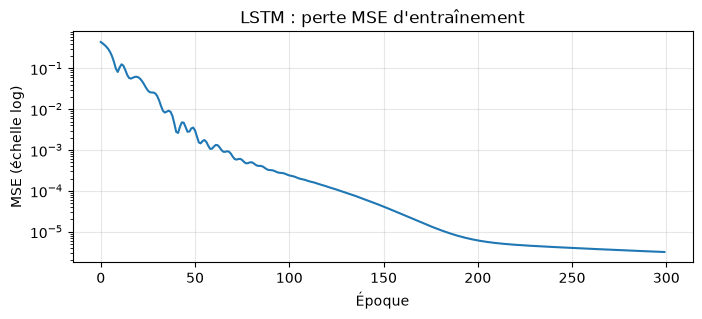

In [5]:
plt.figure(figsize=(8, 3))
plt.plot(historique)
plt.yscale("log")
plt.title("LSTM : perte MSE d'entraînement")
plt.xlabel("Époque")
plt.ylabel("MSE (échelle log)")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Tester

In [6]:
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)
    mae_test = (predictions - y_test).abs().mean()

print(f"MSE test : {erreur_test.item():.6f}")
print(f"MAE test : {mae_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

MSE test : 0.000003
MAE test : 0.001355
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


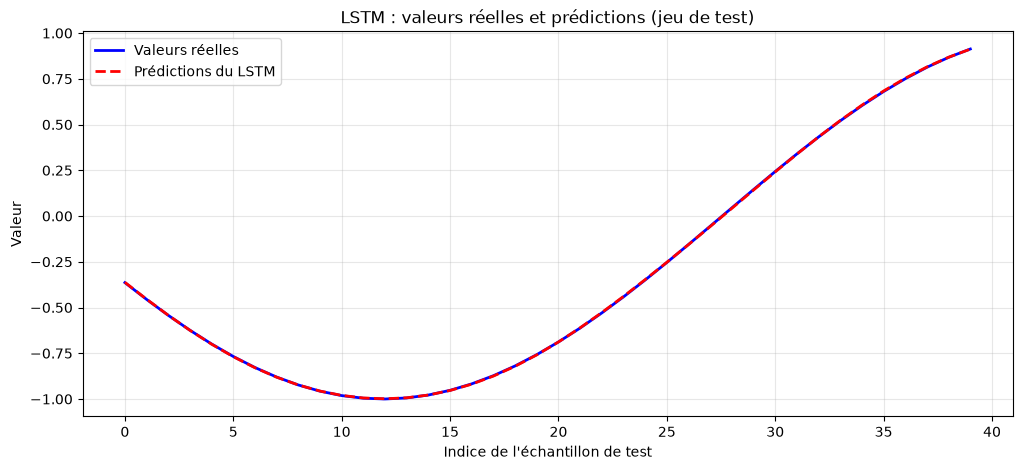

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.reshape(-1), label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(predictions.reshape(-1), label="Prédictions du LSTM", color="red", linestyle="--", linewidth=2)
plt.title("LSTM : valeurs réelles et prédictions (jeu de test)")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Conclusion

- Le LSTM ajoute une **mémoire de cellule** $c_t$ dont la mise à jour est additive : les gradients circulent mieux dans le temps.
- Sur une séquence courte (10 valeurs) et un signal simple, l'avantage sur le RNN est faible ; il devient important sur de longues séquences.
- RNN et LSTM restent **séquentiels** : l'instant $t$ dépend de $t-1$, donc pas de parallélisation sur la longueur.

➡️ Étape suivante : `04_transformer.ipynb`